# Drivers and coverage

`contribution` splits each cell's `fdp` into one term per predictor along the forest's tree
paths (Saabas attribution): per cell, the watershed's baseline plus the contributions equals
`fdp`. `dominant_driver` is the predictor with the largest contribution. This notebook checks
the attribution, shows which predictors carry the model, and counts the buildings the flood
layers reach.

Code: `input-data/tensor/fdp/contrib_fdp.R` (attribution), `ocr.risks.flood.refit` (the store)
and the `buildings` stage. The building counts read the CONUS run of this pipeline at
`STORE` below; set it to a release's output to check that instead.

In [1]:
import json

import duckdb
import fsspec
import matplotlib.pyplot as plt
import pandas as pd

REFIT = 's3://carbonplan-ocr/input/flood/fdp-refit'
RUN = 'noaa-200612-202512'
HUCS = [f'{i:02d}' for i in range(1, 19)]
NAMES = {
    '01': 'New England',
    '02': 'Mid Atlantic',
    '03': 'South Atlantic-Gulf',
    '04': 'Great Lakes',
    '05': 'Ohio',
    '06': 'Tennessee',
    '07': 'Upper Mississippi',
    '08': 'Lower Mississippi',
    '09': 'Souris-Red-Rainy',
    '10': 'Missouri',
    '11': 'Arkansas-White-Red',
    '12': 'Texas-Gulf',
    '13': 'Rio Grande',
    '14': 'Upper Colorado',
    '15': 'Lower Colorado',
    '16': 'Great Basin',
    '17': 'Pacific Northwest',
    '18': 'California',
}
fs = fsspec.filesystem('s3')


def record(path):
    return json.loads(fs.cat_file(f'{REFIT}/{path}'))


BLUE, ORANGE, GRAY = '#2a78d6', '#eb6834', '#9aa5b1'
plt.rcParams.update(
    {'axes.spines.top': False, 'axes.spines.right': False, 'figure.dpi': 110, 'font.size': 9}
)
pd.set_option('display.max_rows', 40)


STORE = 's3://carbonplan-ocr/scratch/shane/flood/v0.0.0-fdp-conus'
DRIVERS = record(f'runs/{RUN}/planar/huc01/contributions.json')['drivers']

## 1. The attribution adds up

Every watershed passes both checks the attribution runs before it writes: the node values it
derives reproduce the leaf values ranger stored, and baseline plus contributions reproduces
`fdp.tif` to within 3e-8. The baselines sit between 0.495 and 0.507 because the forests
train on equal numbers of presences and absences.

In [2]:
checks = pd.DataFrame(
    {
        huc: {
            k: v
            for k, v in record(f'runs/{RUN}/planar/huc{huc}/contributions.json').items()
            if k in ('baseline', 'cells', 'leaf_error', 'max_reconstruction_error')
        }
        for huc in HUCS
    }
).T
print(f'baseline: {checks["baseline"].min():.3f} to {checks["baseline"].max():.3f}')
print(f'max leaf error: {checks["leaf_error"].max():g}')
print(f'max |baseline + contributions - fdp|: {checks["max_reconstruction_error"].max():.1e}')

baseline: 0.495 to 0.507
max leaf error: 0
max |baseline + contributions - fdp|: 3.0e-08


## 2. Importance by watershed

ranger's impurity importance of each predictor, as a share of the watershed's total. Land
cover (`nlcd`) has the lowest share in 10 of the 18 watersheds and hydric soils in 7. The
pseudo-absences are matched to the presences by land-cover class, which leaves land cover
little to separate them by.

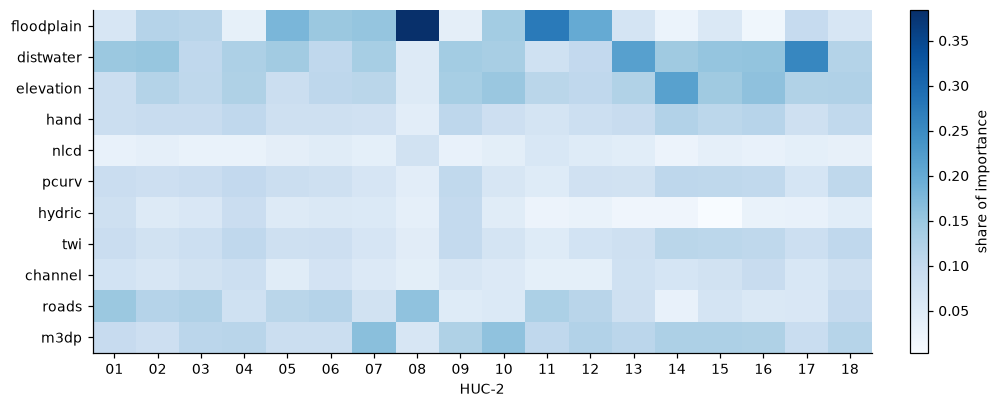

lowest share, by watershed: {'nlcd': 10, 'hydric': 7, 'floodplain': 1}


In [3]:
importance = pd.DataFrame(
    {
        huc: pd.read_csv(f'{REFIT}/runs/{RUN}/planar/huc{huc}/importance.csv', index_col=0)[
            'importance'
        ]
        for huc in HUCS
    }
)
share = importance / importance.sum()
fig, ax = plt.subplots(figsize=(9, 3.6), layout='constrained')
im = ax.imshow(share.loc[DRIVERS].values, cmap='Blues', aspect='auto')
ax.set(
    xticks=range(len(HUCS)),
    xticklabels=HUCS,
    yticks=range(len(DRIVERS)),
    yticklabels=DRIVERS,
    xlabel='HUC-2',
)
fig.colorbar(im, ax=ax, label='share of importance')
plt.show()
print('lowest share, by watershed:', share.idxmin().value_counts().to_dict())

## 3. Buildings

The `buildings` stage samples every layer at each building's centroid. A building whose
cell has no `fdp` keeps a missing value: 1.13% of buildings across CONUS. The share is
highest in Florida (5.21%), then Rhode Island, New Jersey, Massachusetts, Illinois and New
Mexico.

In [4]:
con = duckdb.connect()
con.sql(
    "INSTALL httpfs; LOAD httpfs; CREATE SECRET (TYPE s3, PROVIDER credential_chain, REGION 'us-west-2')"
)
con.sql(
    f"CREATE VIEW b AS SELECT * FROM read_parquet('{STORE}/vector/buildings.geoparquet', can_have_nan = true)"
)
total, missing = con.sql(
    'SELECT count(*), count(*) FILTER (WHERE fdp IS NULL OR isnan(fdp)) FROM b'
).fetchall()[0]
print(f'buildings: {total:,}; without fdp: {missing:,} ({missing / total:.2%})')

buildings: 155,230,989; without fdp: 1,759,991 (1.13%)


In [5]:
STATES = {
    '01': 'AL', '04': 'AZ', '05': 'AR', '06': 'CA', '08': 'CO', '09': 'CT', '10': 'DE', '11': 'DC',
    '12': 'FL', '13': 'GA', '16': 'ID', '17': 'IL', '18': 'IN', '19': 'IA', '20': 'KS', '21': 'KY',
    '22': 'LA', '23': 'ME', '24': 'MD', '25': 'MA', '26': 'MI', '27': 'MN', '28': 'MS', '29': 'MO',
    '30': 'MT', '31': 'NE', '32': 'NV', '33': 'NH', '34': 'NJ', '35': 'NM', '36': 'NY', '37': 'NC',
    '38': 'ND', '39': 'OH', '40': 'OK', '41': 'OR', '42': 'PA', '44': 'RI', '45': 'SC', '46': 'SD',
    '47': 'TN', '48': 'TX', '49': 'UT', '50': 'VT', '51': 'VA', '53': 'WA', '54': 'WV', '55': 'WI',
    '56': 'WY',
}  # fmt: skip
by_state = con.sql(
    """SELECT substr(GEOID, 1, 2) AS fips, count(*) AS buildings,
         count(*) FILTER (WHERE fdp IS NULL OR isnan(fdp)) AS without_fdp
       FROM b GROUP BY 1"""
).df()
by_state['state'] = by_state.fips.map(STATES)
by_state['share'] = by_state.without_fdp / by_state.buildings
by_state = by_state.sort_values('share', ascending=False).set_index('state')
by_state[['buildings', 'without_fdp', 'share']].head(10).style.format(
    {'buildings': '{:,}', 'without_fdp': '{:,}', 'share': '{:.2%}'}
)

,buildings,without_fdp,share
state,,,
FL,"8,321,706","433,595",5.21%
RI,"440,867","20,349",4.62%
NJ,"2,876,026","92,240",3.21%
MA,"2,744,920","87,006",3.17%
IL,"5,880,511","165,032",2.81%
NM,"1,231,134","32,947",2.68%
SC,"2,881,365","53,090",1.84%
DE,"429,447","7,491",1.74%
NY,"6,431,448","106,608",1.66%


## 4. Dominant drivers at buildings

Road density is the dominant driver at 43.7% of buildings and distance to stream at 12.4%;
no other predictor dominates at more than 9%. Road density marks where people live, which is
also where flood damage gets reported, so its weight here likely reflects the reporting bias
of the presences as much as flood exposure. The attribution explains the model, not the
cause of damage.

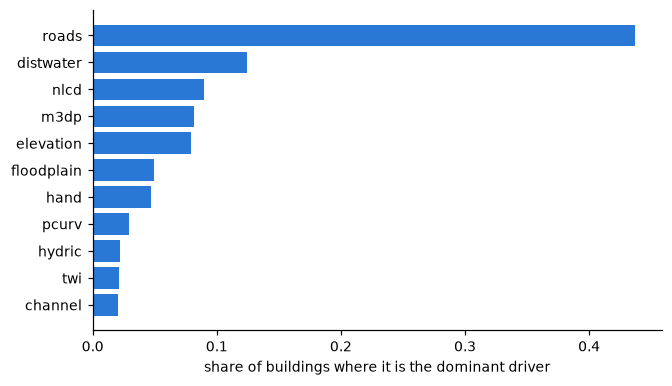

,n,share
driver,,
roads,"67,028,549",43.7%
distwater,"19,070,270",12.4%
nlcd,"13,719,986",8.9%
m3dp,"12,527,931",8.2%
elevation,"12,181,699",7.9%
floodplain,"7,551,504",4.9%
hand,"7,200,629",4.7%
pcurv,"4,470,148",2.9%
hydric,"3,337,825",2.2%


In [6]:
dominant = con.sql(
    'SELECT dominant_driver, count(*) AS n FROM b WHERE dominant_driver IS NOT NULL GROUP BY 1'
).df()
dominant['driver'] = dominant.dominant_driver.map(dict(enumerate(DRIVERS)))
dominant['share'] = dominant.n / dominant.n.sum()
dominant = dominant.sort_values('share', ascending=False).set_index('driver')
fig, ax = plt.subplots(figsize=(6, 3.4), layout='constrained')
ax.barh(dominant.index, dominant.share, color=BLUE)
ax.set(xlabel='share of buildings where it is the dominant driver')
ax.invert_yaxis()
plt.show()
dominant[['n', 'share']].style.format({'n': '{:,}', 'share': '{:.1%}'})